# 03 · Modelos base de los dos objetivos y primeros experimentos en MLflow

Proyecto «Playlist perfecta para viajes en grupo» · NPD Entertainment · CEBANC · Ander Ameztoy

Lee la capa gold que deja la etapa de Big Data (`pipeline.sh` exporta `gold.objetivo1` y `gold.candidatas` a `data/dataset/`) y entrena:

- **Objetivo 1 (regresión de `tasa_no_salto`)**: modelo base 1 (media de la persona), modelo base 2 (gusto por el artista), Ridge y Gradient Boosting. Validación con GroupKFold por canción en el lote 1 y prueba final, una sola vez, en el lote 2. Métricas: MAE (principal), RMSE, R² y Spearman.
- **Objetivo 2 (recomendador)**: modelo base = las N canciones más escuchadas del grupo, frente a la playlist del sistema (percentil por persona, mínimo del grupo y desempate por la media). Se evalúa en el lote 2 con la tasa de salto real de cada miembro y NDCG@N, con N = 50 (20 y 100 de sensibilidad).

Todos los experimentos se registran en MLflow. Las decisiones que aplica están en el informe v1.5 (secciones 6 y 9) y en el notebook 02.

Uso de IA (nivel VERDE): notebook escrito con ayuda de Claude y revisado por Ander.

## 0. Configuración

In [1]:
from pathlib import Path
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore", category=UserWarning)

try:
    from google.colab import drive
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    drive.mount("/content/drive")
    RAIZ = Path("/content/drive/MyDrive/proyecto-Ebaluacion1")
else:
    RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATASET = RAIZ / "data" / "dataset"
FIGURAS = RAIZ / "notebooks" / "figuras"; FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA = RAIZ / "data" / "salida"; SALIDA.mkdir(parents=True, exist_ok=True)

SEMILLA = 42
N_PLAYLIST = [20, 50, 100]          # N principal = 50
N_PRINCIPAL = 50
COLOR = {"modelo base 1": "#B9B6AE", "modelo base 2": "#8C8A83", "Ridge": "#56BE91", "Gradient Boosting": "#FD3B1F"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlelocation": "left"})
print("Entorno:", "Google Colab" if EN_COLAB else "local", "| datos:", DATASET)

Mounted at /content/drive
Entorno: Google Colab | datos: /content/drive/MyDrive/proyecto-Ebaluacion1/data/dataset


### MLflow

- **En el ordenador, con el Docker levantado:** se usa el servidor del proyecto, `http://localhost:5000`.
- **Sin servidor (Colab, o el ordenador sin Docker):** los experimentos se guardan en una base de datos SQLite (`mlflow.db`) y sus artefactos en `mlartifacts/`. En Colab, la última celda los copia a `proyecto-Ebaluacion1/mlflow/` en Drive. Para verlos en tu ordenador, descarga esa carpeta y ejecuta dentro: `mlflow ui --backend-store-uri sqlite:///mlflow.db`.

In [2]:
try:
    import mlflow
except ImportError:
    if EN_COLAB:
        os.system("pip install -q mlflow")
        import mlflow
    else:
        mlflow = None
        print("AVISO: mlflow no está instalado; los resultados se calculan igual pero no se registran.")

if mlflow is not None:
    uri = os.environ.get("MLFLOW_TRACKING_URI")
    if uri is None:
        try:
            import urllib.request
            urllib.request.urlopen("http://localhost:5000", timeout=2)
            uri = "http://localhost:5000"
        except Exception:
            # Sin servidor: base de datos SQLite (MLflow ya no admite la carpeta mlruns/).
            # En Colab se trabaja en el disco local (SQLite no se lleva bien con Drive) y al final
            # se copia a la carpeta del proyecto (sección 5).
            carpeta_mlflow = Path("/content/mlflow") if EN_COLAB else RAIZ / "mlflow"
            carpeta_mlflow.mkdir(parents=True, exist_ok=True)
            os.chdir(carpeta_mlflow)                      # los artefactos van a ./mlartifacts
            uri = f"sqlite:///{carpeta_mlflow / 'mlflow.db'}"
    mlflow.set_tracking_uri(uri)
    print("MLflow en:", uri)

class Registro:
    """Abre una ejecución de MLflow si está disponible; si no, no hace nada."""
    def __init__(self, experimento, nombre):
        self.activo = mlflow is not None
        if self.activo:
            mlflow.set_experiment(experimento)
            self.run = mlflow.start_run(run_name=nombre)
    def params(self, d):
        if self.activo: mlflow.log_params(d)
    def metricas(self, d):
        if self.activo: mlflow.log_metrics({k: float(v) for k, v in d.items() if pd.notna(v)})
    def figura(self, ruta):
        if self.activo: mlflow.log_artifact(str(ruta))
    def modelo(self, m, nombre):
        if not self.activo:
            return
        import mlflow.sklearn
        # Los modelos los entrenamos aquí mismo, así que es seguro confiar en los tipos internos de los
        # árboles de HistGradientBoosting al guardarlos con skops (formato de las versiones nuevas de MLflow).
        confianza = ["sklearn.ensemble._hist_gradient_boosting.predictor.TreePredictor"]
        try:
            mlflow.sklearn.log_model(m, name=nombre, skops_trusted_types=confianza)
        except TypeError:                     # versiones de MLflow anteriores a la 3
            mlflow.sklearn.log_model(m, nombre)
        except Exception as e:                # que un fallo al guardar el modelo no pare el notebook
            print(f"AVISO: no se pudo guardar el modelo en MLflow ({type(e).__name__}); las métricas sí quedan registradas.")
    def cerrar(self):
        if self.activo: mlflow.end_run()

MLflow en: sqlite:////content/mlflow/mlflow.db


## 1. Carga del gold

Si los CSV no están en `data/dataset/`: en local se descomprime el zip que haya en esa carpeta; en Colab, la celda siguiente busca en Google Drive el `gold_para_ander.zip` más reciente (también entre los archivos compartidos contigo), lo descarga y lo descomprime ahí. La primera vez pide permiso para acceder a Drive con tu cuenta.

In [3]:
import zipfile, io
NOMBRE_ZIP = "gold_para_ander.zip"
DATASET.mkdir(parents=True, exist_ok=True)
faltan = [f for f in ("gold_objetivo1.csv", "gold_candidatas.csv") if not (DATASET / f).exists()]

if faltan and EN_COLAB:
    from google.colab import auth
    from googleapiclient.discovery import build
    from googleapiclient.http import MediaIoBaseDownload
    auth.authenticate_user()
    servicio = build("drive", "v3")
    res = servicio.files().list(q=f"name = '{NOMBRE_ZIP}' and trashed = false", orderBy="modifiedTime desc",
                                fields="files(id, name, modifiedTime, owners(emailAddress))", pageSize=5,
                                includeItemsFromAllDrives=True, supportsAllDrives=True).execute()["files"]
    if not res:
        raise FileNotFoundError(f"No encuentro {NOMBRE_ZIP} en tu Drive: pide a Daniel que te lo comparta.")
    zf = res[0]
    print(f"Descargando {zf['name']} ({zf['modifiedTime']}, de {zf['owners'][0]['emailAddress']})")
    buf = io.BytesIO()
    descarga = MediaIoBaseDownload(buf, servicio.files().get_media(fileId=zf["id"]))
    hecho = False
    while not hecho:
        _, hecho = descarga.next_chunk()
    with zipfile.ZipFile(buf) as z:
        for nombre in z.namelist():
            if nombre.endswith(".csv"):
                (DATASET / Path(nombre).name).write_bytes(z.read(nombre))   # sin rutas del zip
                print("  ->", DATASET / Path(nombre).name)
elif faltan:
    zips = sorted(DATASET.glob("*.zip"), key=lambda z: z.stat().st_mtime)
    if not zips:
        raise FileNotFoundError(f"Faltan {faltan} en {DATASET}. Pon ahí los CSV o {NOMBRE_ZIP}.")
    with zipfile.ZipFile(zips[-1]) as z:
        for nombre in z.namelist():
            if nombre.endswith(".csv"):
                (DATASET / Path(nombre).name).write_bytes(z.read(nombre))
    print("CSV del gold descomprimidos desde", zips[-1])
else:
    print("Los CSV del gold ya están en", DATASET)

Los CSV del gold ya están en /content/drive/MyDrive/proyecto-Ebaluacion1/data/dataset


In [4]:
o1 = pd.read_csv(DATASET / "gold_objetivo1.csv", encoding="utf-8-sig")
cand = pd.read_csv(DATASET / "gold_candidatas.csv", encoding="utf-8-sig")
print(f"gold_objetivo1: {o1.shape[0]:,} filas × {o1.shape[1]} columnas".replace(",", "."))
print(f"gold_candidatas: {cand.shape[0]:,} filas, {cand['track_id'].nunique():,} canciones".replace(",", "."))

datos = o1[o1["fiable"] == 1].copy()
datos.groupby(["lote", "persona"]).agg(filas=("track_id", "size"), canciones=("track_id", "nunique"),
                                       tasa_media=("tasa_no_salto", "mean")).round(3)

gold_objetivo1: 85.105 filas × 21 columnas
gold_candidatas: 249.072 filas. 10.378 canciones


filas  canciones  tasa_media
lote persona                                       
1    persona_358ed916   2581       1114       0.943
     persona_744b89e7   8738       1486       0.538
2    persona_358ed916   1888        957       0.939
     persona_744b89e7   6720       1540       0.459

## 2. Objetivo 1 · Variables sin fuga de datos

**Fuga de datos detectada y corregida (20 de noviembre).** En la primera versión del gold, las tasas de persona, contexto, artista y álbum se calculaban restando a un total fijo las escuchas de la propia canción (*leave-one-out*). Dentro de una persona, lo único que movía la variable era esa canción, así que llevaba escondida la etiqueta (correlación de −0,6 con `tasa_no_salto` en el lote 1), y un modelo de árboles parecía casi perfecto en la validación (R² ≈ 0,9) sin mejorar nada en el lote 2. Daniel lo corrigió en `gold.sql` (commit `26eec34`): `per_tasa_no_salto` y `per_tasa_no_salto_ctx` pasan a ser constantes por persona y contexto, y del artista y el álbum solo quedan recuentos.

**Cómo se calculan aquí las variables**, a partir de los recuentos del gold (filas del lote 1 con `n_escuchas` y `n_no_salto`):

- **Persona (E) y persona en el contexto (E'):** tasa total de la persona y de la persona en ese contexto, **sin restar** la canción. Es una constante por persona (o por persona y contexto), así que no puede filtrar la etiqueta.
- **Artista (B) y álbum (B'):** se calculan **fuera de pliegue**. En la validación, las filas de cada pliegue usan solo las otras canciones del entrenamiento; las filas de entrenamiento, un segundo GroupKFold interno. En la prueba final (lote 2), se usa todo el lote 1 sin las escuchas de la propia canción.
- **Resto del grupo (G)** y `per_pct_shuffle`: se usan tal cual del gold. G sale de las escuchas de los otros miembros, que se conocen en el momento de recomendar.

In [5]:
fuente = o1[o1["lote"] == 1]          # todas las filas del lote 1 (también las de menos de 5 escuchas): los recuentos

def tasa_suave(ns, n, previa, k=5):
    """Tasa con suavizado hacia la tasa de la persona: con pocas escuchas no se fía del todo."""
    return (ns + k * previa) / (n + k)

def codificar(filas, src):
    """Variables de persona, contexto, artista y álbum de 'filas' a partir de los recuentos de 'src',
    sin contar nunca las escuchas de la propia canción por la propia persona."""
    f = filas[["persona", "track_id", "artista", "album", "franja", "tipo_dia"]].copy()
    per = src.groupby("persona")[["n_escuchas", "n_no_salto"]].sum()
    f["per_tasa"] = f["persona"].map(per["n_no_salto"] / per["n_escuchas"])
    ctx = src.groupby(["persona", "franja", "tipo_dia"])[["n_escuchas", "n_no_salto"]].sum()
    f = f.join((ctx["n_no_salto"] / ctx["n_escuchas"]).rename("ctx_tasa"), on=["persona", "franja", "tipo_dia"])
    propia = src.groupby(["persona", "track_id"])[["n_escuchas", "n_no_salto"]].sum()
    f = f.join(propia.rename(columns=lambda c: "own_" + c), on=["persona", "track_id"])
    for nombre, claves in [("art", ["persona", "artista"]), ("alb", ["persona", "artista", "album"])]:
        g = src.groupby(claves)[["n_escuchas", "n_no_salto"]].sum()
        f = f.join(g.rename(columns=lambda c: f"{nombre}_{c}_tot"), on=claves)
        n = f[f"{nombre}_n_escuchas_tot"].fillna(0) - f["own_n_escuchas"].fillna(0)
        ns = f[f"{nombre}_n_no_salto_tot"].fillna(0) - f["own_n_no_salto"].fillna(0)
        f[f"{nombre}_n"] = np.log1p(n.clip(lower=0))
        f[f"{nombre}_tasa"] = tasa_suave(ns.clip(lower=0), n.clip(lower=0), f["per_tasa"])
        f[f"{nombre}_conocido"] = (n > 0).astype(int)
    return f

def matriz(filas, cod):
    X = pd.DataFrame({
        "per_tasa": cod["per_tasa"], "ctx_tasa": cod["ctx_tasa"].fillna(cod["per_tasa"]),
        "art_tasa": cod["art_tasa"], "art_n": cod["art_n"], "art_conocido": cod["art_conocido"],
        "alb_tasa": cod["alb_tasa"], "alb_n": cod["alb_n"], "alb_conocido": cod["alb_conocido"],
        "per_pct_shuffle": filas["per_pct_shuffle"].to_numpy(),
        "grp_n": np.log1p(filas["grp_n_escuchas"].clip(lower=0)).to_numpy(),
        "grp_tasa": filas["grp_tasa_no_salto"].fillna(cod["per_tasa"]).to_numpy(),
        "grp_conocido": filas["grp_tasa_no_salto"].notna().astype(int).to_numpy(),
        "fin_semana": (filas["tipo_dia"] != "laborable").astype(int).to_numpy(),
    }, index=filas.index)
    for f in range(6):
        X[f"franja_{f}"] = (filas["franja"].astype(int) == f).astype(int).to_numpy()
    return X

def variables_oof(filas, src, k=5):
    """Variables de entrenamiento fuera de pliegue: cada grupo de canciones se codifica con las demás."""
    partes = []
    for tr, te in GroupKFold(k).split(filas, groups=filas["track_id"]):
        canciones_te = set(filas.iloc[te]["track_id"])
        sub = src[~src["track_id"].isin(canciones_te)]
        partes.append(matriz(filas.iloc[te], codificar(filas.iloc[te], sub)))
    return pd.concat(partes).loc[filas.index]

lote1, lote2 = datos[datos["lote"] == 1].reset_index(drop=True), datos[datos["lote"] == 2].reset_index(drop=True)
y1, y2 = lote1["tasa_no_salto"].to_numpy(), lote2["tasa_no_salto"].to_numpy()
peso1 = np.sqrt(lote1["n_escuchas"].to_numpy())
grupos = lote1["track_id"]
X1 = variables_oof(lote1, fuente)                         # entrenamiento final: fuera de pliegue
X2 = matriz(lote2, codificar(lote2, fuente))             # prueba: todo el lote 1 sin la propia canción
nuevas = ~lote2["track_id"].isin(set(lote1["track_id"]))
print(f"Lote 1: {len(lote1):,} filas | lote 2: {len(lote2):,} filas | {X1.shape[1]} variables | "
      f"filas del lote 2 de canciones nuevas: {int(nuevas.sum()):,}".replace(",", "."))

# Comprobación de la fuga: dentro de cada persona, la variable de persona del gold debe ser constante
chk = pd.DataFrame({"persona": lote1["persona"], "gold_per": lote1["per_tasa_no_salto"], "nuevo_per": X1["per_tasa"]})
chk.groupby("persona").agg(
    variacion_per_tasa_gold=("gold_per", lambda v: round(v.max() - v.min(), 4)),
    variacion_per_tasa_notebook=("nuevo_per", lambda v: round(v.max() - v.min(), 4)))

Lote 1: 11.319 filas | lote 2: 8.608 filas | 19 variables | filas del lote 2 de canciones nuevas: 3.616


,variacion_per_tasa_gold,variacion_per_tasa_notebook
persona,,
persona_358ed916,0.0,0.0017
persona_744b89e7,0.0,0.0063


## 3. Objetivo 1 · Modelos

In [6]:
def metricas(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
            "R2": r2_score(y, p), "Spearman": spearmanr(y, p).statistic}

class Base1:   # media de la persona: su tasa general sin esta canción
    def fit(self, X, y, **kw): return self
    def predict(self, X): return X["per_tasa"].to_numpy()

class Base2:   # gusto por el artista (si no lo conoce, la tasa general de la persona)
    def fit(self, X, y, **kw): return self
    def predict(self, X): return X["art_tasa"].to_numpy()

MODELOS = {
    "modelo base 1": (lambda: Base1(), {"tipo": "media de la persona"}),
    "modelo base 2": (lambda: Base2(), {"tipo": "gusto por el artista (art_tasa, suavizado)"}),
    "Ridge": (lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0)), {"alpha": 1.0}),
    "Gradient Boosting": (lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                                                min_samples_leaf=40, l2_regularization=1.0,
                                                                random_state=SEMILLA),
                          {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 15, "min_samples_leaf": 40}),
}

def ajustar(m, X, y, w):
    if hasattr(m, "steps"):
        m.fit(X, y, **{m.steps[-1][0] + "__sample_weight": w})
    elif isinstance(m, (Base1, Base2)):
        m.fit(X, y)
    else:
        m.fit(X, y, sample_weight=w)
    return m

# Variables de cada pliegue de validación, calculadas sin ver las canciones de validación
PLIEGUES = {}
for tr, te in GroupKFold(5).split(lote1, groups=grupos):
    tr, te = tuple(tr), tuple(te)
    entrena = lote1.iloc[list(tr)]
    src_tr = fuente[fuente["track_id"].isin(set(entrena["track_id"]))]
    Xtr = variables_oof(entrena, src_tr)
    Xte = matriz(lote1.iloc[list(te)], codificar(lote1.iloc[list(te)], src_tr))
    PLIEGUES[(tr, te)] = (Xtr, Xte)

resultados, predicciones = [], {}
for nombre, (crear, params) in MODELOS.items():
    # Validación: GroupKFold por canción en el lote 1
    oof = np.zeros(len(y1))
    for (tr, te), (Xtr, Xte) in PLIEGUES.items():
        tr, te = np.array(tr), np.array(te)
        oof[te] = np.clip(ajustar(crear(), Xtr, y1[tr], peso1[tr]).predict(Xte), 0, 1)
    cv = metricas(y1, oof)
    # Prueba final: reentrenar con todo el lote 1 y predecir el lote 2 una sola vez
    final = ajustar(crear(), X1, y1, peso1)
    p2 = np.clip(final.predict(X2), 0, 1)
    predicciones[nombre] = p2
    prueba = metricas(y2, p2)
    prueba_nuevas = metricas(y2[nuevas], p2[nuevas])
    resultados.append({"modelo": nombre, **{f"CV {k}": v for k, v in cv.items()},
                       **{f"lote 2 {k}": v for k, v in prueba.items()},
                       "lote 2 MAE (canciones nuevas)": prueba_nuevas["MAE"]})

    r = Registro("objetivo1_tasa_no_salto", nombre)
    r.params({**params, "modelo": nombre, "validacion": "GroupKFold(5) por track_id en lote 1",
              "prueba": "lote 2 (desde 2025-07-01)", "filas_lote1": len(y1), "filas_lote2": len(y2),
              "variables": X1.shape[1], "min_escuchas": 5})
    r.metricas({f"cv_{k.lower()}": v for k, v in cv.items()} | {f"test_{k.lower()}": v for k, v in prueba.items()}
               | {"test_mae_canciones_nuevas": prueba_nuevas["MAE"]})
    if nombre in ("Ridge", "Gradient Boosting"):
        r.modelo(final, "modelo")
    r.cerrar()

tabla_o1 = pd.DataFrame(resultados).set_index("modelo").round(3)
tabla_o1.to_csv(SALIDA / "03_resultados_objetivo1.csv")
tabla_o1

2026/11/20 11:58:30 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/20 11:58:30 INFO mlflow.store.db.utils: Updating database tables
2026/11/20 11:58:42 INFO mlflow.tracking.fluent: Experiment with name 'objetivo1_tasa_no_salto' does not exist. Creating a new experiment.


,CV MAE,CV RMSE,CV R2,CV Spearman,lote 2 MAE,lote 2 RMSE,lote 2 R2,lote 2 Spearman,lote 2 MAE (canciones nuevas)
modelo,,,,,,,,,
modelo base 1,0.179,0.227,0.358,0.429,0.206,0.257,0.331,0.632,0.192
modelo base 2,0.178,0.231,0.332,0.532,0.214,0.272,0.245,0.519,0.193
Ridge,0.167,0.214,0.427,0.613,0.208,0.262,0.303,0.502,0.194
Gradient Boosting,0.167,0.216,0.414,0.610,0.207,0.263,0.294,0.566,0.191


In [7]:
# Resultado por persona en el lote 2 (MAE): ¿el modelo funciona igual para los dos?
por_persona = pd.DataFrame({n: pd.Series(np.abs(p - y2)).groupby(lote2["persona"]).mean() for n, p in predicciones.items()}).round(3)
por_persona.index.name = "persona (MAE en el lote 2)"
por_persona

,modelo base 1,modelo base 2,Ridge,Gradient Boosting
persona (MAE en el lote 2),,,,
persona_358ed916,0.096,0.094,0.092,0.091
persona_744b89e7,0.237,0.247,0.240,0.240


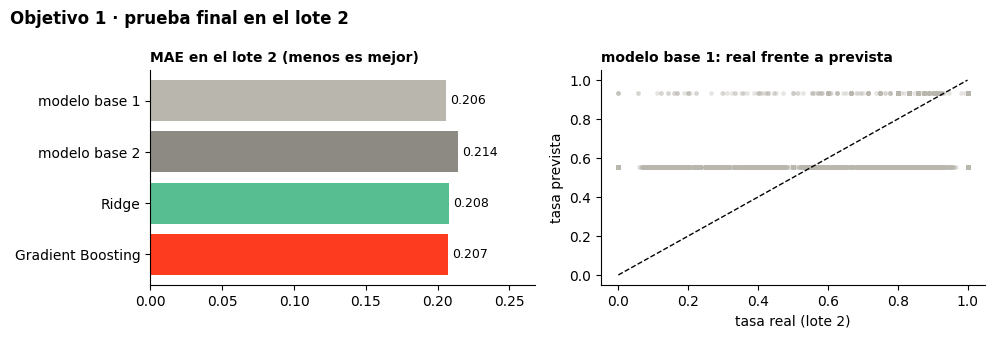

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
t = tabla_o1
axes[0].barh(t.index[::-1], t["lote 2 MAE"][::-1], color=[COLOR[m] for m in t.index[::-1]])
for i, v in enumerate(t["lote 2 MAE"][::-1]):
    axes[0].text(v + 0.003, i, f"{v:.3f}", va="center", fontsize=9)
axes[0].set_title("MAE en el lote 2 (menos es mejor)", fontsize=10); axes[0].set_xlim(0, t["lote 2 MAE"].max() * 1.25)
mejor = t["lote 2 MAE"].idxmin()
axes[1].scatter(y2, predicciones[mejor], s=6, alpha=0.25, color=COLOR[mejor])
axes[1].plot([0, 1], [0, 1], color="#020202", lw=1, ls="--")
axes[1].set_xlabel("tasa real (lote 2)"); axes[1].set_ylabel("tasa prevista")
axes[1].set_title(f"{mejor}: real frente a prevista", fontsize=10)
fig.suptitle("Objetivo 1 · prueba final en el lote 2", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
ruta = FIGURAS / "03_objetivo1_resultados.png"; fig.savefig(ruta, dpi=200, bbox_inches="tight"); plt.show()

In [9]:
# Qué variables usa el modelo lineal (coeficientes estandarizados de la Ridge)
ridge = ajustar(MODELOS["Ridge"][0](), X1, y1, peso1)
coef = pd.Series(ridge[-1].coef_, index=X1.columns).sort_values(key=np.abs, ascending=False)
coef.head(10).round(3).to_frame("coeficiente (variables estandarizadas)")

,coeficiente (variables estandarizadas)
per_tasa,-0.875
per_pct_shuffle,-0.827
ctx_tasa,0.156
art_tasa,0.041
alb_tasa,0.037
art_conocido,0.011
art_n,-0.011
alb_n,0.008
franja_0,-0.008
alb_conocido,0.007


## 4. Objetivo 2 · Recomendador: modelo base frente a la playlist del sistema

Para cada contexto del viaje (franja × tipo de día, 12 en total):

- **Modelo base (referencia):** las N canciones con más escuchas del grupo en el lote 1.
- **Sistema (v0):** gusto de cada miembro = su tasa real del lote 1 si tiene 5 o más escuchas en ese contexto; si no, la que predice el mejor modelo del objetivo 1. Se pasa a percentil dentro de las candidatas de esa persona en ese contexto, el gusto del grupo es el **mínimo** de los percentiles y los empates se resuelven con la **media** (decisión del 20 de noviembre).

**Evaluación en el lote 2** (decisión del 20 de noviembre): para cada miembro, la tasa de salto real de las canciones de la lista que escuchó al menos 5 veces en ese contexto en el lote 2 (ponderada por escuchas), y NDCG@N con su tasa real de no salto como relevancia. Después, media de los miembros y de los contextos. No se exige que todos los miembros hayan escuchado cada canción, porque en el lote 2 casi no hay canciones así (notebook 02, sección 7).

In [10]:
mejor = tabla_o1["CV MAE"].drop(["modelo base 1", "modelo base 2"]).idxmin()   # elegido por validación, no por el lote 2
modelo_o1 = ajustar(MODELOS[mejor][0](), X1, y1, peso1)
print("Modelo del objetivo 1 que usa el sistema (elegido por la validación cruzada):", mejor)

c = cand.copy()
c["prevista"] = np.clip(modelo_o1.predict(matriz(c, codificar(c, fuente))[X1.columns]), 0, 1)
c["gusto"] = c["tasa_real_lote1"].fillna(c["prevista"])            # real si hay 5 o más escuchas en el lote 1
c["origen"] = np.where(c["tasa_real_lote1"].notna(), "real", "prevista")
c["percentil"] = c.groupby(["persona", "franja", "tipo_dia"])["gusto"].rank(pct=True)

grupo = (c.groupby(["track_id", "franja", "tipo_dia"])
          .agg(gusto_grupo=("percentil", "min"), desempate=("percentil", "mean"),
               escuchas_grupo_l1=("n_lote1", "sum"))
          .reset_index())
c["origen"].value_counts(normalize=True).mul(100).round(1).to_frame("% de gustos de miembro")

Modelo del objetivo 1 que usa el sistema (elegido por la validación cruzada): Ridge


,% de gustos de miembro
origen,
prevista,95.5
real,4.5


In [11]:
def ndcg(relevancias):
    """NDCG de una lista ya ordenada; relevancias = tasa real de no salto (0-1)."""
    rel = np.asarray(relevancias, dtype=float)
    if len(rel) == 0 or rel.max() == 0: return np.nan
    desc = 1 / np.log2(np.arange(2, len(rel) + 2))
    return float((rel * desc).sum() / (np.sort(rel)[::-1] * desc).sum())

real2 = c[c["tasa_real_lote2"].notna()][["persona", "track_id", "franja", "tipo_dia", "n_lote2", "tasa_real_lote2"]]

def evaluar(lista, n):
    """lista: DataFrame con track_id, franja, tipo_dia ordenado por posición dentro de cada contexto."""
    filas = []
    for (f, t), l in lista.groupby(["franja", "tipo_dia"]):
        top = l.head(n).assign(posicion=np.arange(min(n, len(l))))
        ev = top.merge(real2[(real2["franja"] == f) & (real2["tipo_dia"] == t)], on=["track_id", "franja", "tipo_dia"])
        for p, e in ev.groupby("persona"):
            e = e.sort_values("posicion")
            salto = 1 - np.average(e["tasa_real_lote2"], weights=e["n_lote2"])
            filas.append({"franja": f, "tipo_dia": t, "persona": p, "canciones_evaluadas": len(e),
                          "tasa_salto": salto, "ndcg": ndcg(e["tasa_real_lote2"])})
    r = pd.DataFrame(filas)
    por_persona = r.groupby("persona")[["tasa_salto", "ndcg", "canciones_evaluadas"]].mean()
    return por_persona, r

referencia = grupo.sort_values(["franja", "tipo_dia", "escuchas_grupo_l1"], ascending=[True, True, False])
sistema = grupo.sort_values(["franja", "tipo_dia", "gusto_grupo", "desempate"], ascending=[True, True, False, False])

filas = []
for n in N_PLAYLIST:
    for nombre, lista in [("modelo base (más escuchadas)", referencia), ("sistema v0", sistema)]:
        pp, _ = evaluar(lista, n)
        fila = {"N": n, "lista": nombre, "tasa de salto (media de miembros)": pp["tasa_salto"].mean(),
                "NDCG@N (media de miembros)": pp["ndcg"].mean(),
                "canciones evaluadas por contexto y miembro": pp["canciones_evaluadas"].mean()}
        fila |= {f"tasa de salto {p}": v for p, v in pp["tasa_salto"].items()}
        filas.append(fila)
        r = Registro("objetivo2_recomendador", f"{nombre} · N={n}")
        r.params({"lista": nombre, "N": n, "combinacion": "mínimo de percentiles, desempate por la media" if "sistema" in nombre else "más escuchadas del grupo en el lote 1",
                  "modelo_objetivo1": mejor if "sistema" in nombre else "-", "evaluacion": "lote 2, por miembro, canciones con 5 o más escuchas"})
        r.metricas({"tasa_salto": fila["tasa de salto (media de miembros)"], "ndcg": fila["NDCG@N (media de miembros)"],
                    **{f"tasa_salto_{p}": v for p, v in pp["tasa_salto"].items()}})
        r.cerrar()

tabla_o2 = pd.DataFrame(filas).set_index(["N", "lista"]).round(3)
tabla_o2.to_csv(SALIDA / "03_resultados_objetivo2.csv")
tabla_o2

2026/11/20 11:59:11 INFO mlflow.tracking.fluent: Experiment with name 'objetivo2_recomendador' does not exist. Creating a new experiment.


tasa de salto (media de miembros)  \
N   lista                                                             
20  modelo base (más escuchadas)                              0.319   
    sistema v0                                                0.343   
50  modelo base (más escuchadas)                              0.297   
    sistema v0                                                0.337   
100 modelo base (más escuchadas)                              0.302   
    sistema v0                                                0.310   

                                  NDCG@N (media de miembros)  \
N   lista                                                      
20  modelo base (más escuchadas)                       0.926   
    sistema v0                                         0.972   
50  modelo base (más escuchadas)                       0.913   
    sistema v0                                         0.950   
100 modelo base (más escuchadas)                       0.903   
    sistema v0                                         0.934   

                                  canciones evaluadas por contexto y miembro  \
N   lista                                                                      
20  modelo base (más escuchadas)                                       5.182   
    sistema v0                                                         4.681   
50  modelo base (más escuchadas)                                      11.803   
    sistema v0                                                         7.500   
100 modelo base (más escuchadas)                                      19.973   
    sistema v0                                                        11.118   

                                  tasa de salto persona_358ed916  \
N   lista                                                          
20  modelo base (más escuchadas)                           0.000   
    sistema v0                                             0.112   
50  modelo base (más escuchadas)                           0.000   
    sistema v0                                             0.088   
100 modelo base (más escuchadas)                           0.017   
    sistema v0                                             0.061   

                                  tasa de salto persona_744b89e7  
N   lista                                                         
20  modelo base (más escuchadas)                           0.638  
    sistema v0                                             0.574  
50  modelo base (más escuchadas)                           0.595  
    sistema v0                                             0.585  
100 modelo base (más escuchadas)                           0.588  
    sistema v0                                             0.559

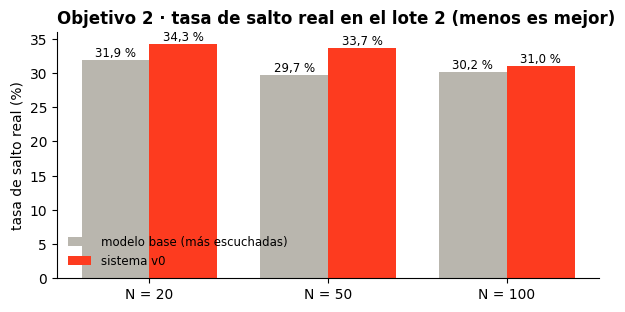

In [12]:
t = tabla_o2["tasa de salto (media de miembros)"].unstack("lista")
fig, ax = plt.subplots(figsize=(7, 3.2))
x = np.arange(len(t)); w = 0.38
for k, (col, color) in enumerate(zip(t.columns, ["#B9B6AE", "#FD3B1F"])):
    ax.bar(x + (k - 0.5) * w, t[col] * 100, w, color=color, label=col)
    for i, v in enumerate(t[col] * 100):
        ax.text(x[i] + (k - 0.5) * w, v + 0.5, f"{v:.1f} %".replace(".", ","), ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels([f"N = {n}" for n in t.index]); ax.set_ylabel("tasa de salto real (%)")
ax.set_title("Objetivo 2 · tasa de salto real en el lote 2 (menos es mejor)")
ax.legend(frameon=False, fontsize=8.5)
ruta = FIGURAS / "03_objetivo2_tasa_salto.png"; fig.savefig(ruta, dpi=200, bbox_inches="tight"); plt.show()

In [13]:
n = N_PRINCIPAL
base = tabla_o2.loc[(n, "modelo base (más escuchadas)"), "tasa de salto (media de miembros)"]
sist = tabla_o2.loc[(n, "sistema v0"), "tasa de salto (media de miembros)"]
print(f"Hipótesis (N = {n}): tasa de salto real del sistema {sist:.1%} frente a {base:.1%} de la lista de las más escuchadas.")
print("Se cumple en esta primera versión." if sist < base else "No se cumple todavía: hay que mejorar el sistema antes de la entrega final.")
json.dump({"objetivo1": tabla_o1.reset_index().to_dict("records"), "objetivo2": tabla_o2.reset_index().to_dict("records"),
           "modelo_sistema": mejor}, open(SALIDA / "03_resumen.json", "w", encoding="utf-8"), ensure_ascii=False, indent=1, default=float)

Hipótesis (N = 50): tasa de salto real del sistema 33.7% frente a 29.7% de la lista de las más escuchadas.
No se cumple todavía: hay que mejorar el sistema antes de la entrega final.


## 5. Guardar los experimentos de MLflow en Drive (solo Colab)

In [14]:
if EN_COLAB and mlflow is not None and mlflow.get_tracking_uri().startswith("sqlite"):
    import shutil
    destino = RAIZ / "mlflow"
    destino.mkdir(parents=True, exist_ok=True)
    shutil.copy2("/content/mlflow/mlflow.db", destino / "mlflow.db")
    if Path("/content/mlflow/mlartifacts").exists():
        shutil.copytree("/content/mlflow/mlartifacts", destino / "mlartifacts", dirs_exist_ok=True)
    print("Experimentos copiados a", destino)
    print("Ejecuciones registradas:")
    display(mlflow.search_runs(search_all_experiments=True)[["experiment_id", "tags.mlflow.runName", "status"]])

Experimentos copiados a /content/drive/MyDrive/proyecto-Ebaluacion1/mlflow
Ejecuciones registradas:


,experiment_id,tags.mlflow.runName,status
0,2,sistema v0 · N=100,FINISHED
1,2,modelo base (más escuchadas) · N=100,FINISHED
2,2,sistema v0 · N=50,FINISHED
3,2,modelo base (más escuchadas) · N=50,FINISHED
4,2,sistema v0 · N=20,FINISHED
5,2,modelo base (más escuchadas) · N=20,FINISHED
6,1,Gradient Boosting,FINISHED
7,1,Ridge,FINISHED
8,1,modelo base 2,FINISHED
9,1,modelo base 1,FINISHED
